# checkbox detector (YOLO)

dataset used: [cogniquest-idc1w/checkboxes-xtv3p v5](https://universe.roboflow.com/cogniquest-idc1w/checkboxes-xtv3p/dataset/5) (CC BY 4.0, 2421 train, 206 validation, 206 test scanned pages, stretched to 1280x1280). Weights are saved to `models/checkbox_yolo.pt`.

The export has 6 overlapping classes (`Checkbox-Checked`, `Checkbox-UnChecked`, `Checked`, `check`, `checked`, `unchecked`). I merge them into a single `checkbox` class: the detector only has to find boxes, deciding checked/unchecked stays with the CNN classifier (see `cnn.ipynb`).

The model is trained on the raw scans, not on the binarized output of the preprocessing service, so at inference it expects the grayscale page (as 3 channels).

In [1]:
import os

# Set the ROCm override version for your graphics card
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "10.3.0"

# Verify that it was set correctly
print("HSA_OVERRIDE_GFX_VERSION is set to:", os.environ.get("HSA_OVERRIDE_GFX_VERSION"))

HSA_OVERRIDE_GFX_VERSION is set to: 10.3.0


In [ ]:
import random
import shutil
import zipfile
from pathlib import Path

import cv2
import torch
import yaml
from PIL import Image, ImageDraw
from ultralytics import YOLO

from services.detection import get_detection_service
from services.preprocessing import get_preprocessing_service
from tests.evaluation import IOU_THRESHOLD, DetectionResult, load_all_samples, match

random.seed(0)

ROOT = Path.cwd()
ZIP_PATH = ROOT / "checkboxes.v5i.yolov8.zip"
DATASET_DIR = ROOT / "datasets" / "checkboxes"
DATA_YAML = DATASET_DIR / "data.yaml"
YOLO_MODEL_PATH = ROOT / "models" / "checkbox_yolo.pt"

BASE_WEIGHTS = "yolo26s.pt"  # small model: nano misses tiny boxes, medium is slow to train
IMGSZ = 1280  # checkboxes are only a few dozen pixels, downscaling the 1280px pages would lose them
CONF = 0.25
DEVICE = 0 if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("warning: no CUDA device found, training on CPU will take many hours")

## Data

In [3]:
SPLITS = ["train", "valid", "test"]

if not DATASET_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATASET_DIR)

# Merge every class into 0 = checkbox. Only the class id is rewritten, the coordinates stay as they are.
for label_file in DATASET_DIR.glob("*/labels/*.txt"):
    lines = [line.split(maxsplit=1) for line in label_file.read_text().splitlines() if line.strip()]
    label_file.write_text("".join(f"0 {coords}\n" for _, coords in lines))

# Ultralytics caches parsed labels next to the label folders, a stale cache would keep the old class ids.
for cache in DATASET_DIR.glob("*/labels*.cache"):
    cache.unlink()

# The exported data.yaml uses paths relative to a folder that doesn't exist here, so write a fresh one.
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {0: "checkbox"},
}))
print(DATA_YAML.read_text())

names:
  0: checkbox
path: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes
test: test/images
train: train/images
val: valid/images



In [4]:
def read_boxes(label_file: Path) -> list[tuple[float, float, float, float]]:
    """YOLO label file -> normalized (cx, cy, w, h) boxes."""
    return [tuple(map(float, line.split()[1:5])) for line in label_file.read_text().splitlines()]


for split in SPLITS:
    label_files = sorted((DATASET_DIR / split / "labels").glob("*.txt"))
    sides = sorted(min(w, h) * IMGSZ for f in label_files for _, _, w, h in read_boxes(f))
    print(f"{split:5}: {len(label_files):4} images, {len(sides):5} boxes, median box side {sides[len(sides) // 2]:.0f}px")

train: 2420 images, 31203 boxes, median box side 18px
valid:  205 images,  2619 boxes, median box side 20px
test :  205 images,  2313 boxes, median box side 18px


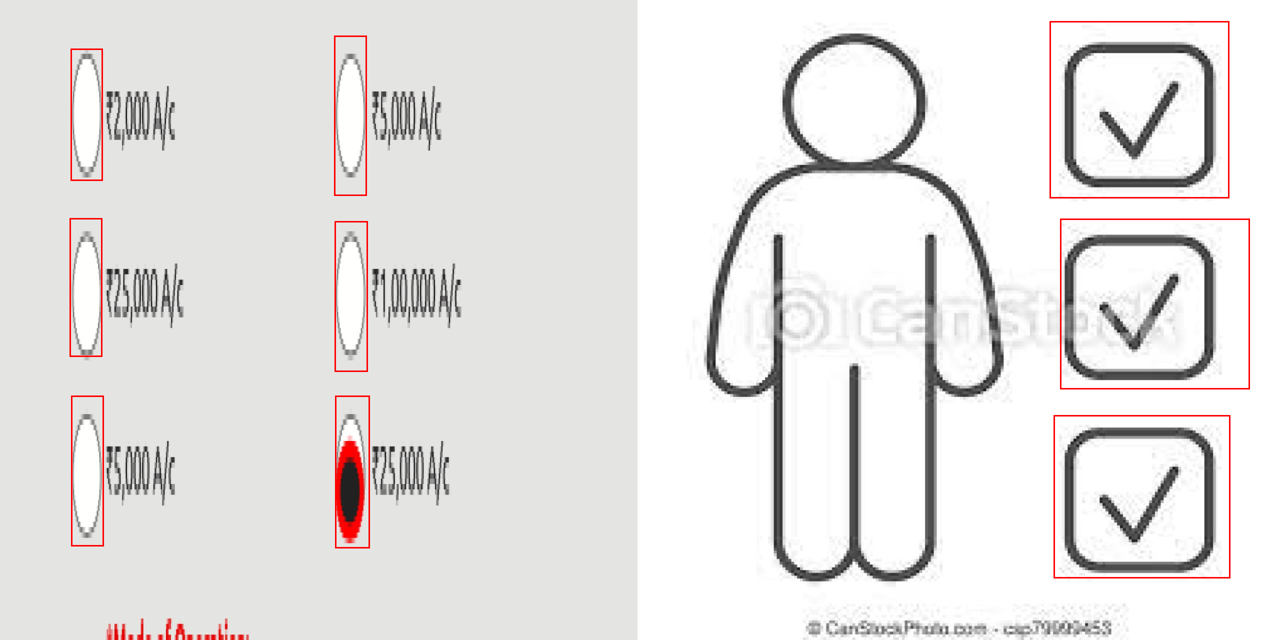

In [5]:
# Two random training pages with their labelled boxes.
previews = []
for image_path in random.sample(sorted((DATASET_DIR / "train" / "images").iterdir()), 2):
    img = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(img)
    for cx, cy, w, h in read_boxes(DATASET_DIR / "train" / "labels" / f"{image_path.stem}.txt"):
        draw.rectangle([(cx - w / 2) * img.width, (cy - h / 2) * img.height,
                        (cx + w / 2) * img.width, (cy + h / 2) * img.height], outline="red", width=3)
    previews.append(img.resize((640, 640)))

grid = Image.new("RGB", (1280, 640), "white")
for i, img in enumerate(previews):
    grid.paste(img, (i * 640, 0))
grid

## Train

In [6]:
model = YOLO(BASE_WEIGHTS)
results = model.train(
    data=DATA_YAML,
    imgsz=IMGSZ,
    epochs=100,
    patience=20,  # stop early once validation mAP stops improving
    batch=-1 if DEVICE != "cpu" else 8,  # -1 = AutoBatch, fills ~60% of the GPU memory
    device=DEVICE,
    seed=0,
    project=ROOT / "runs",
    name="checkbox_yolo",
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.196 🚀 Python-3.13.5 torch-2.14.1+rocm7.2 CUDA:0 (AMD Radeon RX 6700 XT, 12272MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, 

[W1101 00:27:19.620028597 HIPCachingAllocator.cpp:3935] memory allocation failed with OOM on device 0 while trying to allocate 79691776 bytes (free: 0, total: 12868124672).
[W1101 00:27:19.765014319 HIPCachingAllocator.cpp:3935] memory allocation failed with OOM on device 0 while trying to allocate 79691776 bytes (free: 0, total: 12868124672).


CUDA out of memory. Tried to allocate 400.00 MiB. GPU 0 has a total capacity of 11.98 GiB of which 36.00 MiB is free. Of the allocated memory 10.91 GiB is allocated by PyTorch, and 239.23 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)
AutoBatch: Using batch-size 4 for CUDA:0 3.11G/11.52G (27%) ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 223.4±46.5 MB/s, size: 190.1 KB)


[W1101 00:27:39.581790056 HIPCachingAllocator.cpp:3935] memory allocation failed with OOM on device 0 while trying to allocate 419430400 bytes (free: 0, total: 12868124672).
[W1101 00:27:39.585804588 HIPCachingAllocator.cpp:3935] memory allocation failed with OOM on device 0 while trying to allocate 419430400 bytes (free: 37748736, total: 12868124672).


train: Scanning /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/train/labels.cache... 2420 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2420/2420 922.7Mit/s 0.0s
train: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/train/images/0ad24b57_page_3_jpg.rf.367a88ded9d4ff80e5d4bd92a70609d1.jpg: 11 duplicate labels removed
train: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/train/images/16109_jpg.rf.2f6257e011ddfedbf7485c614f09a0c8.jpg: 1 duplicate labels removed
train: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/train/images/1be7b805_page_5_jpg.rf.2c56b3d408980679a814170a474eb72a.jpg: 1 duplicate labels removed
train: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/train/images/40907a81_page_11_jpg.rf.c02889976f9d43e9e2cc8f164c0eaa12.jpg: 1 duplicate labels removed
train: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/train/images/615a8275_page_1_jpg.rf.169ece6742082d8b

In [7]:
YOLO_MODEL_PATH.parent.mkdir(exist_ok=True)
shutil.copy(Path(results.save_dir) / "weights" / "best.pt", YOLO_MODEL_PATH)
print(f"saved best model to {YOLO_MODEL_PATH}")

saved best model to /home/tomas/Interviews/HomeVisionTHSubmission/models/checkbox_yolo.pt


## Test

The test split is scored once, with the saved weights loaded from `models/`, so the file itself gets exercised as well.

In [8]:
test_model = YOLO(YOLO_MODEL_PATH)
metrics = test_model.val(data=DATA_YAML, split="test", imgsz=IMGSZ, device=DEVICE, plots=False)
print(f"mAP50={metrics.box.map50:.3f}  mAP50-95={metrics.box.map:.3f}  "
      f"precision={metrics.box.mp:.3f}  recall={metrics.box.mr:.3f}")

Ultralytics 8.4.196 🚀 Python-3.13.5 torch-2.14.1+rocm7.2 CUDA:0 (AMD Radeon RX 6700 XT, 12272MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 154.5±95.4 MB/s, size: 143.3 KB)
val: Scanning /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/test/labels... 205 images, 1 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 205/205 3.8Kit/s 0.1s
val: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/test/images/019758_png.rf.d3c50af667ff158dc7e82ad7076c9bcb.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/test/images/55871f40_page_1_jpg.rf.47d75608f500d3c737222b8382145ede.jpg: 1 duplicate labels removed
val: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes/test/images/f8fc5e2a_page_22_jpg.rf.a19a73b4484f04a4e2183384e1460bd3.jpg: 1 duplicate labels removed
val: New cache c

## Repo benchmark

The same pages and matching as the pytest detection report (`data/<dataset>`, IoU >= 0.5), with the OpenCV contour detector side by side.

In [14]:
def yolo_find_checkboxes(gray) -> list[list[int]]:
    """Grayscale page -> checkbox boxes as [x, y, w, h], the same convention as DetectionService."""
    result = test_model.predict(cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR), imgsz=IMGSZ, conf=CONF,
                                device=DEVICE, verbose=False)[0]
    return [[round(x1), round(y1), round(x2 - x1), round(y2 - y1)] for x1, y1, x2, y2 in result.boxes.xyxy.tolist()]


def opencv_find_checkboxes(gray) -> list[list[int]]:
    return get_detection_service().find_checkboxes(get_preprocessing_service().cleanup_image(gray))


def fmt(value):
    return "-" if value is None else f"{value:.2f}"


samples = load_all_samples()
detectors = {"yolo": yolo_find_checkboxes, "opencv": opencv_find_checkboxes}
totals = {}
print(f"IoU >= {IOU_THRESHOLD}")
print(f"{'sample':24} {'detector':8} {'GT':>5} {'pred':>5} {'TP':>5} {'prec':>6} {'recall':>6} {'F1':>6}")
for sample in samples:
    gray = sample.load_gray()
    truths = [a.bbox for a in sample.annotations]
    for name, find in detectors.items():
        preds = find(gray)
        r = DetectionResult(match(preds, truths), len(preds), len(truths))
        key = (sample.dataset, name)
        totals[key] = totals[key] + r if key in totals else r
        print(f"{sample.id:24} {name:8} {r.n_gt:5} {r.n_pred:5} {r.tp:5} {fmt(r.precision):>6} {fmt(r.recall):>6} {fmt(r.f1):>6}")
print()
for (dataset, name), r in sorted(totals.items()):
    print(f"{dataset + ' (total)':24} {name:8} {r.n_gt:5} {r.n_pred:5} {r.tp:5} {fmt(r.precision):>6} {fmt(r.recall):>6} {fmt(r.f1):>6}")

IoU >= 0.5
sample                   detector    GT  pred    TP   prec recall     F1
fullres/canvas3.png      yolo        48    48    48   1.00   1.00   1.00
fullres/canvas3.png      opencv      48    74    48   0.65   1.00   0.79
fullres/canvas1.png      yolo       118    90    89   0.99   0.75   0.86
fullres/canvas1.png      opencv     118   154   118   0.77   1.00   0.87
fullres/canvas2.png      yolo        43    43    42   0.98   0.98   0.98
fullres/canvas2.png      opencv      43    82    40   0.49   0.93   0.64
fullres/canvas4.png      yolo        79    81    79   0.98   1.00   0.99
fullres/canvas4.png      opencv      79    85    79   0.93   1.00   0.96
lowres/canvas3.png       yolo        48    48    48   1.00   1.00   1.00
lowres/canvas3.png       opencv      48    63    48   0.76   1.00   0.86
lowres/canvas1.png       yolo       118   116   115   0.99   0.97   0.98
lowres/canvas1.png       opencv     118   128   116   0.91   0.98   0.94
lowres/canvas2.png       yolo        43 

fullres/canvas3.png


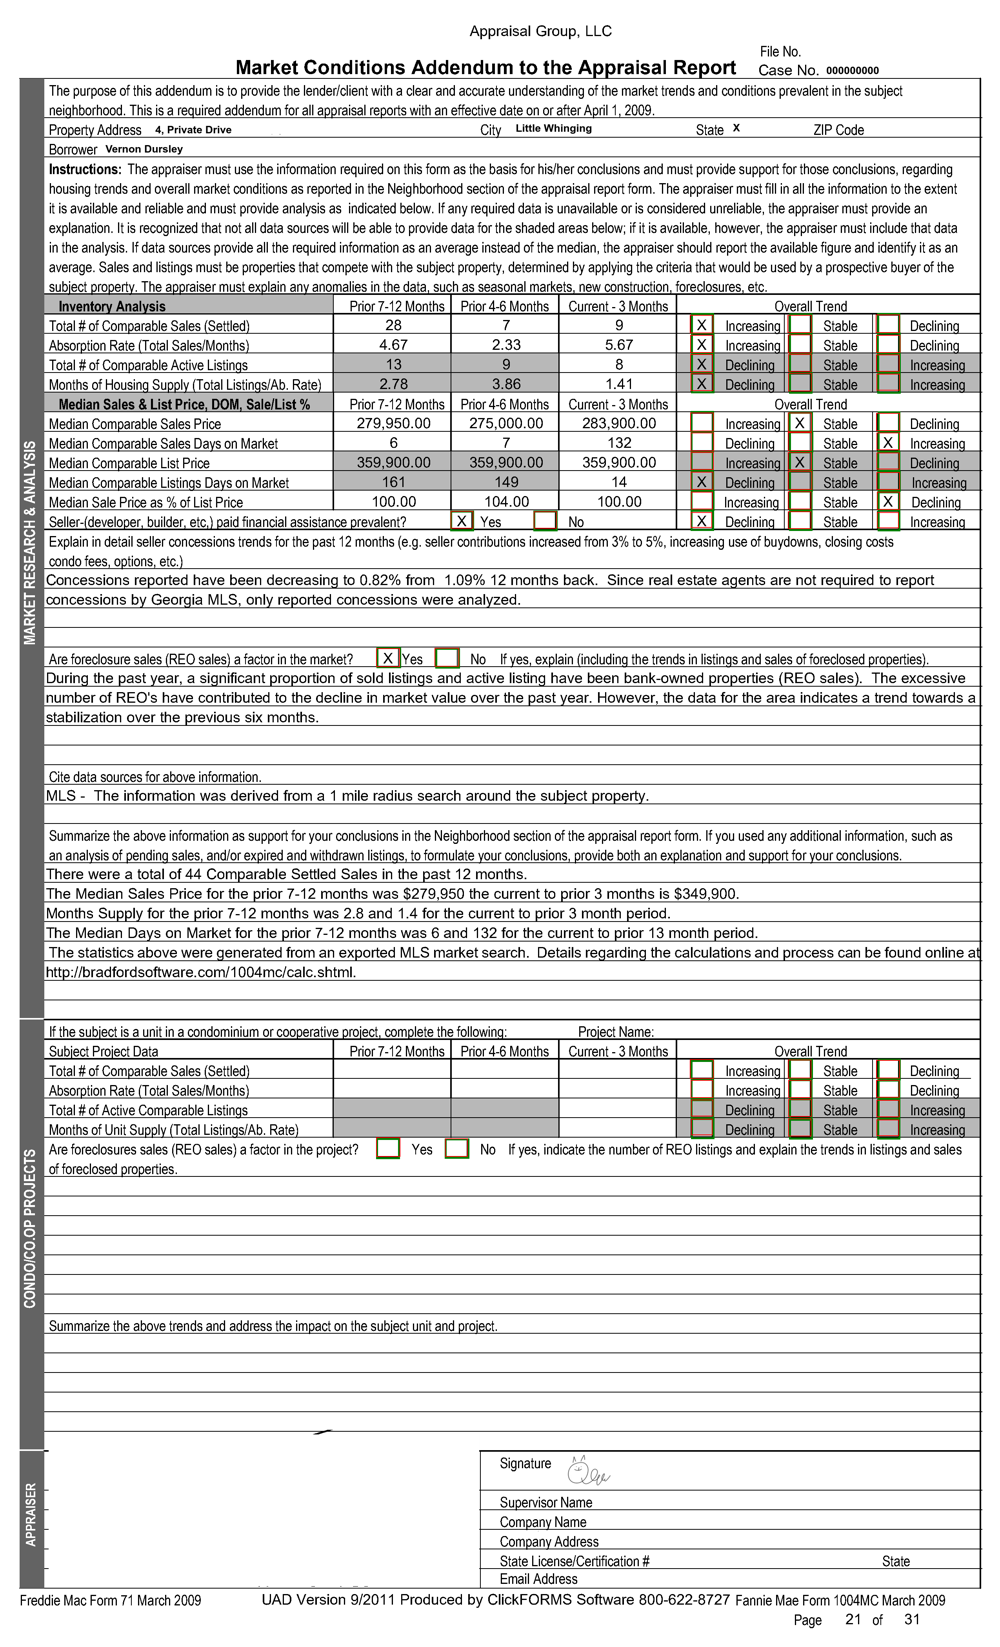

In [10]:
# YOLO boxes (red) vs. labelled boxes (green) on one page, to eyeball misses and false positives.
sample = samples[0]
gray = sample.load_gray()
page = Image.fromarray(gray).convert("RGB")
draw = ImageDraw.Draw(page)
for x, y, w, h in (a.bbox for a in sample.annotations):
    draw.rectangle([x, y, x + w, y + h], outline="green", width=5)
for x, y, w, h in yolo_find_checkboxes(gray):
    draw.rectangle([x, y, x + w, y + h], outline="red", width=2)
print(sample.id)
page.resize((1000, round(page.height * 1000 / page.width)))